# Day 10 (Lite): Generative AI – Synthesizing Dog Images (GAN & Diffusion)

**Goal:** train a **GAN** to create new 64 x 64 dog images from random noise, show how it improves over epochs, then compare it with a **pre-trained diffusion model**.

**Before running:** Runtime → Change runtime type → **T4 GPU** → Save. Then **Runtime → Run all**.

**If Colab restarts:** just **Run all** again. Training **resumes from the last saved checkpoint** in your Google Drive.

## 0. Settings, GPU and Google Drive
Checkpoints, image grids and the prepared dataset are saved to Google Drive, so nothing is lost if Colab restarts.
Change `N_IMAGES` / `EPOCHS` here if you want a shorter or longer run.

In [ ]:
import os, glob, json, time, zipfile
import xml.etree.ElementTree as ET
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import kagglehub

# Let TensorFlow and PyTorch (diffusion, later) share the GPU
for g in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError:
        pass
print("GPU:", tf.config.list_physical_devices("GPU"))

# ---- Settings (Lite: adjusts automatically to GPU or CPU) ----
HAS_GPU = len(tf.config.list_physical_devices("GPU")) > 0
if HAS_GPU:
    N_IMAGES, EPOCHS = 10000, 25    # GPU: ~10-15 min training
else:
    N_IMAGES, EPOCHS = 4000, 12     # CPU only: smaller run (~30-45 min); results are blurrier
print(f"{'GPU' if HAS_GPU else 'CPU only'} mode: {N_IMAGES} images, {EPOCHS} epochs")
IMG_SIZE   = 64
BATCH      = 64
LATENT_DIM = 100     # size of the random noise vector
SAVE_EVERY = 2       # save a checkpoint every N epochs

# ---- Google Drive (for save points) ----
try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/day10_gan"
except Exception as e:
    print("Drive not available, saving locally instead:", e)
    WORK = "/content/day10_gan"
os.makedirs(f"{WORK}/grids", exist_ok=True)
print("Saving to:", WORK)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU mode: 10000 images, 25 epochs
Mounted at /content/drive
Saving to: /content/drive/MyDrive/day10_gan


## 1. Load and prepare the dog images
- Download the Kaggle *Stanford Dogs* dataset (~20,580 dog photos with bounding boxes, ~750 MB).
- If bounding-box annotations are available, **crop each photo to the dog** (much better training data than whole photos with backgrounds). Otherwise use a centre crop.
- Resize to **64 x 64** and scale pixels to **[-1, 1]**, the same range as the generator's `tanh` output.
- The prepared array is saved to Drive, so this slow step only runs once.

Using Colab cache for faster access to the 'stanford-dogs-dataset' dataset.
Downloaded to: /kaggle/input/stanford-dogs-dataset
Dog photos found: 20580
Annotation files found: 20580
  processed 0 files, 1 crops
  processed 2000 files, 2163 crops
  processed 4000 files, 4312 crops
  processed 6000 files, 6467 crops
  processed 8000 files, 8627 crops
Deleted the raw download to free disk space
Prepared and saved: (10000, 64, 64, 3)


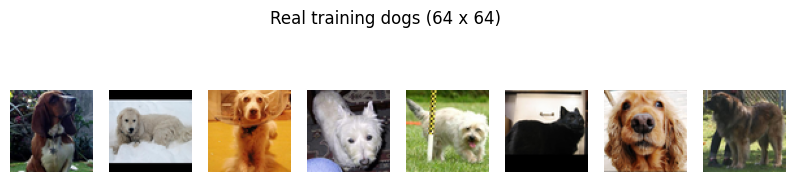

Batches per epoch: 156


In [ ]:
cache_file = f"{WORK}/dogs_{IMG_SIZE}_{N_IMAGES}.npy"

if os.path.exists(cache_file):
    X = np.load(cache_file)
    print("Loaded prepared images from Drive:", X.shape)
else:
    path = kagglehub.dataset_download("jessicali9530/stanford-dogs-dataset")
    print("Downloaded to:", path)

    # Unzip any zip files (the dataset may ship as all-dogs.zip / Annotation.zip)
    for z in glob.glob(f"{path}/**/*.zip", recursive=True):
        out = z[:-4]
        if not os.path.exists(out):
            with zipfile.ZipFile(z) as f:
                f.extractall(out)

    files = sorted(glob.glob(f"{path}/**/*.jpg", recursive=True))
    print("Dog photos found:", len(files))

    # Annotation files are named after the image id (e.g. n02085620_7)
    ann = {}
    for a in glob.glob(f"{path}/**/Annotation/**/*", recursive=True):
        if os.path.isfile(a):
            ann[os.path.basename(a)] = a
    print("Annotation files found:", len(ann))

    def dog_crops(fp):
        img = Image.open(fp).convert("RGB")
        key = os.path.splitext(os.path.basename(fp))[0]
        boxes = []
        if key in ann:
            try:
                for obj in ET.parse(ann[key]).getroot().iter("bndbox"):
                    b = [int(obj.find(t).text) for t in ("xmin", "ymin", "xmax", "ymax")]
                    boxes.append(b)
            except Exception:
                boxes = []
        if not boxes:                                   # no box → centre square crop
            w, h = img.size; s = min(w, h)
            boxes = [[(w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2]]
        out = []
        for x0, y0, x1, y1 in boxes:
            bw, bh = x1 - x0, y1 - y0
            s = max(bw, bh); cx, cy = (x0 + x1) // 2, (y0 + y1) // 2   # square around the dog
            crop = img.crop((cx - s // 2, cy - s // 2, cx + s // 2, cy + s // 2))
            out.append(np.asarray(crop.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)))
        return out

    rng = np.random.default_rng(42)
    rng.shuffle(files)
    imgs = []
    for i, fp in enumerate(files):
        imgs.extend(dog_crops(fp))
        if len(imgs) >= N_IMAGES:
            break
        if i % 2000 == 0:
            print(f"  processed {i} files, {len(imgs)} crops")
    X = np.stack(imgs[:N_IMAGES]).astype(np.uint8)
    np.save(cache_file, X)
    # Free disk space: the raw photos are no longer needed (the prepared array is saved)
    import shutil
    shutil.rmtree(os.path.expanduser("~/.cache/kagglehub"), ignore_errors=True)
    print("Deleted the raw download to free disk space")
    print("Prepared and saved:", X.shape)

# Show some real training dogs
plt.figure(figsize=(10, 2.5))
for i in range(min(8, len(X))):
    plt.subplot(1, 8, i + 1); plt.imshow(X[i]); plt.axis("off")
plt.suptitle("Real training dogs (64 x 64)"); plt.show()

# Scale to [-1, 1] and build the tf.data pipeline
def to_float(x):
    return (tf.cast(x, tf.float32) - 127.5) / 127.5

dataset = (tf.data.Dataset.from_tensor_slices(X)
           .shuffle(len(X), seed=42)
           .map(to_float, num_parallel_calls=tf.data.AUTOTUNE)
           .batch(BATCH, drop_remainder=True)
           .prefetch(tf.data.AUTOTUNE))
print("Batches per epoch:", len(X) // BATCH)

## 2. Build the two networks (DCGAN)
- **Generator** (the forger): noise vector (100 numbers) → Dense → upsampling with `Conv2DTranspose` (4 → 8 → 16 → 32 → 64) → 64 x 64 x 3 image with `tanh` (values in [-1, 1]).
- **Discriminator** (the detective): image → strided `Conv2D` layers (64 → 32 → 16 → 8 → 4) → one number: "real or fake?" (a logit).
- Standard DCGAN choices: BatchNorm, LeakyReLU, Adam with learning rate 0.0002 and beta_1 = 0.5.

In [ ]:
def build_generator():
    return keras.Sequential([
        layers.Input(shape=(LATENT_DIM,)),
        layers.Dense(4 * 4 * 512, use_bias=False),
        layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Reshape((4, 4, 512)),
        layers.Conv2DTranspose(256, 4, strides=2, padding="same", use_bias=False),   # 8x8
        layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False),   # 16x16
        layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),    # 32x32
        layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(3, 4, strides=2, padding="same", activation="tanh"),  # 64x64x3
    ], name="generator")

def build_discriminator():
    return keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Conv2D(64, 4, strides=2, padding="same"), layers.LeakyReLU(0.2),             # 32x32
        layers.Conv2D(128, 4, strides=2, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.LeakyReLU(0.2),                                  # 16x16
        layers.Conv2D(256, 4, strides=2, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.LeakyReLU(0.2),                                  # 8x8
        layers.Conv2D(512, 4, strides=2, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.LeakyReLU(0.2),                                  # 4x4
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(1),   # logit: high = "real", low = "fake"
    ], name="discriminator")

generator = build_generator()
discriminator = build_discriminator()
print(f"Generator params: {generator.count_params():,}")
print(f"Discriminator params: {discriminator.count_params():,}")

g_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)
bce = keras.losses.BinaryCrossentropy(from_logits=True)

Generator params: 3,609,347
Discriminator params: 2,767,425


## 3. The adversarial training step
Each step has two turns:
1. **Discriminator turn:** shown real dogs (target "real" = 0.9, a little *label smoothing* so it doesn't get over-confident) and fake dogs (target "fake" = 0). It learns to tell them apart.
2. **Generator turn:** makes new fakes and is rewarded when the discriminator calls them "real". Only the generator's weights change in this turn.

In [ ]:
@tf.function
def train_step(real):
    noise = tf.random.normal([tf.shape(real)[0], LATENT_DIM])

    # ---- 1. Discriminator turn ----
    with tf.GradientTape() as tape:
        fake = generator(noise, training=True)
        real_out = discriminator(real, training=True)
        fake_out = discriminator(fake, training=True)
        d_loss = (bce(tf.ones_like(real_out) * 0.9, real_out) +
                  bce(tf.zeros_like(fake_out), fake_out))
    d_grads = tape.gradient(d_loss, discriminator.trainable_variables)
    d_opt.apply_gradients(zip(d_grads, discriminator.trainable_variables))

    # ---- 2. Generator turn ----
    noise = tf.random.normal([tf.shape(real)[0], LATENT_DIM])
    with tf.GradientTape() as tape:
        fake = generator(noise, training=True)
        fake_out = discriminator(fake, training=True)
        g_loss = bce(tf.ones_like(fake_out), fake_out)   # "make the detective say REAL"
    g_grads = tape.gradient(g_loss, generator.trainable_variables)
    g_opt.apply_gradients(zip(g_grads, generator.trainable_variables))

    return d_loss, g_loss

## 4. Save points and image grids
- **Checkpoint** = generator + discriminator + both optimizers + epoch number, saved to Drive every `SAVE_EVERY` epochs.
- A **fixed noise** (64 vectors) is saved once, so every grid shows the *same 64 dogs* improving over time.

In [ ]:
epoch_var = tf.Variable(0, dtype=tf.int64)
ckpt = tf.train.Checkpoint(generator=generator, discriminator=discriminator,
                           g_opt=g_opt, d_opt=d_opt, epoch=epoch_var)
manager = tf.train.CheckpointManager(ckpt, f"{WORK}/checkpoints", max_to_keep=2)

if manager.latest_checkpoint:
    ckpt.restore(manager.latest_checkpoint)
    print(f"Resumed from checkpoint: epoch {int(epoch_var.numpy())} ✅")
else:
    print("No checkpoint found, starting from epoch 0")

noise_file = f"{WORK}/fixed_noise.npy"
if os.path.exists(noise_file):
    fixed_noise = np.load(noise_file)
else:
    fixed_noise = np.random.default_rng(0).normal(size=(64, LATENT_DIM)).astype("float32")
    np.save(noise_file, fixed_noise)

history_file = f"{WORK}/losses.json"
history = json.load(open(history_file)) if os.path.exists(history_file) else {"d": [], "g": []}

def save_grid(epoch):
    imgs = generator(fixed_noise, training=False).numpy()
    imgs = ((imgs + 1) * 127.5).clip(0, 255).astype("uint8")
    grid = imgs.reshape(8, 8, IMG_SIZE, IMG_SIZE, 3).swapaxes(1, 2).reshape(8 * IMG_SIZE, 8 * IMG_SIZE, 3)
    Image.fromarray(grid).save(f"{WORK}/grids/epoch_{epoch:03d}.png")
    return grid

No checkpoint found, starting from epoch 0


## 5. Train the GAN
Prints the losses each epoch and saves a grid of 64 generated dogs at epoch 1, every 5 epochs, and at the end.
**Reading the losses:** they should stay *balanced*. If the discriminator loss goes to ~0 and the generator loss keeps rising, the detective has won and the generator stops learning.

In [ ]:
start_epoch = int(epoch_var.numpy())
t_total = time.time()
for epoch in range(start_epoch + 1, EPOCHS + 1):
    t0 = time.time()
    d_sum = g_sum = 0.0; n = 0
    for real in dataset:
        d_loss, g_loss = train_step(real)
        d_sum += float(d_loss); g_sum += float(g_loss); n += 1
    history["d"].append(d_sum / n); history["g"].append(g_sum / n)
    print(f"Epoch {epoch:3d}/{EPOCHS}  D loss {d_sum/n:.3f}  G loss {g_sum/n:.3f}  ({time.time()-t0:.0f}s)")

    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        save_grid(epoch)
    epoch_var.assign(epoch)
    if epoch % SAVE_EVERY == 0 or epoch == EPOCHS:
        manager.save()
        json.dump(history, open(history_file, "w"))
print(f"Done. Training time this session: {(time.time()-t_total)/60:.1f} min")

Epoch   1/25  D loss 0.961  G loss 7.791  (41s)
Epoch   2/25  D loss 0.873  G loss 3.570  (17s)
Epoch   3/25  D loss 0.895  G loss 3.627  (17s)
Epoch   4/25  D loss 0.832  G loss 3.631  (17s)
Epoch   5/25  D loss 0.826  G loss 3.379  (18s)
Epoch   6/25  D loss 0.847  G loss 3.027  (18s)
Epoch   7/25  D loss 0.838  G loss 3.258  (18s)
Epoch   8/25  D loss 0.840  G loss 3.295  (18s)
Epoch   9/25  D loss 0.809  G loss 3.412  (18s)
Epoch  10/25  D loss 0.788  G loss 3.472  (18s)
Epoch  11/25  D loss 0.794  G loss 3.394  (18s)
Epoch  12/25  D loss 0.777  G loss 3.414  (18s)
Epoch  13/25  D loss 0.793  G loss 3.364  (18s)
Epoch  14/25  D loss 0.845  G loss 3.248  (18s)
Epoch  15/25  D loss 0.815  G loss 3.217  (18s)
Epoch  16/25  D loss 0.830  G loss 3.080  (18s)
Epoch  17/25  D loss 0.830  G loss 3.002  (18s)
Epoch  18/25  D loss 0.815  G loss 3.027  (18s)
Epoch  19/25  D loss 0.836  G loss 2.971  (18s)
Epoch  20/25  D loss 0.819  G loss 3.117  (18s)
Epoch  21/25  D loss 0.814  G loss 3.029

## 6. Results: the same 64 dogs over time

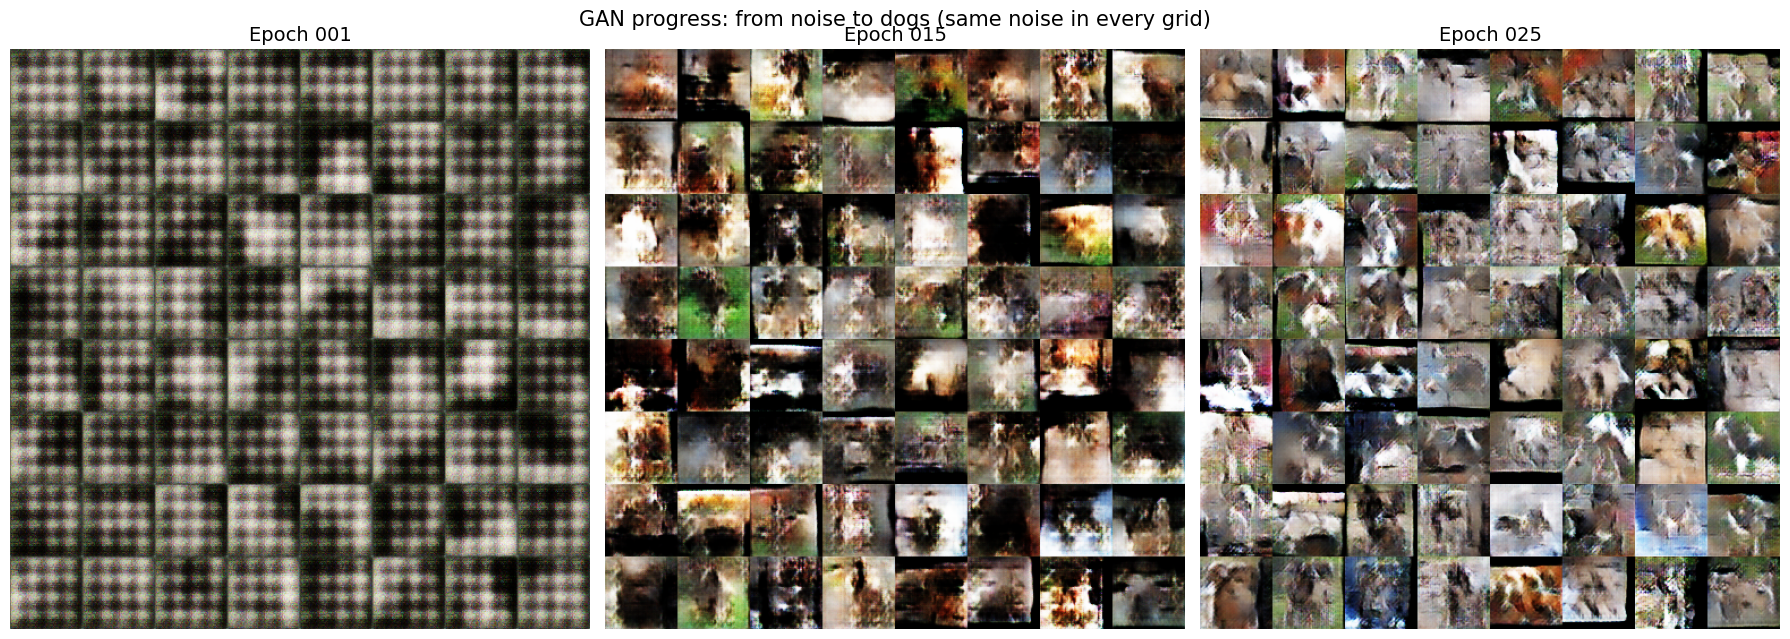

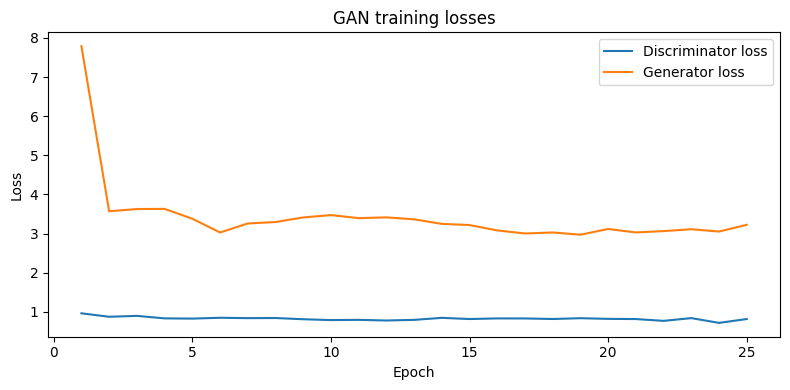

In [ ]:
grid_files = sorted(glob.glob(f"{WORK}/grids/epoch_*.png"))
show = [grid_files[0], grid_files[len(grid_files) // 2], grid_files[-1]] if len(grid_files) >= 3 else grid_files
plt.figure(figsize=(18, 6.5))
for i, f in enumerate(show):
    plt.subplot(1, len(show), i + 1)
    plt.imshow(Image.open(f)); plt.axis("off")
    plt.title(os.path.basename(f).replace(".png", "").replace("_", " ").title(), fontsize=14)
plt.suptitle("GAN progress: from noise to dogs (same noise in every grid)", fontsize=15)
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(history["d"]) + 1), history["d"], label="Discriminator loss")
plt.plot(range(1, len(history["g"]) + 1), history["g"], label="Generator loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("GAN training losses"); plt.legend()
plt.tight_layout(); plt.show()

## 7. Pre-trained diffusion model (Hugging Face `diffusers`)
Generate dogs with **Stable Diffusion v1.5** from a text prompt and measure time per image. Diffusion starts from noise and removes it step by step (25 steps here).
Images are also shown downsized to 64 x 64 to compare fairly with the GAN.

In [1]:
!pip install -q diffusers accelerate
import torch
from diffusers import StableDiffusionPipeline

gen_start = time.time()
fake = generator(tf.random.normal([64, LATENT_DIM]), training=False)
_ = fake.numpy()
gan_ms = (time.time() - gen_start) / 64 * 1000
print(f"GAN: {gan_ms:.2f} ms per image ({generator.count_params()/1e6:.1f}M parameters)")

diff_ok = False
if not HAS_GPU:
    print("No GPU: skipping the diffusion model (it needs a GPU). Run this cell again later with a GPU.")
try:
    assert HAS_GPU, "no GPU"
    pipe = StableDiffusionPipeline.from_pretrained(
        "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16,
        variant="fp16", safety_checker=None).to("cuda")   # fp16 files only = smaller download
    pipe.enable_attention_slicing()                        # uses less GPU memory
    pipe.set_progress_bar_config(disable=True)
    prompts = ["a photo of a dog, high quality"] * 4
    t0 = time.time()
    diff_imgs = pipe(prompts, num_inference_steps=25, height=512, width=512,
                     generator=torch.Generator("cuda").manual_seed(0)).images
    diff_s = (time.time() - t0) / len(diff_imgs)
    n_params = sum(p.numel() for p in pipe.unet.parameters()) / 1e6
    print(f"Diffusion: {diff_s:.2f} s per image (UNet {n_params:.0f}M parameters, 25 steps)")
    diff_ok = True
except Exception as e:
    print("Diffusion model could not run here:", e)

gan_imgs = ((fake.numpy()[:8] + 1) * 127.5).clip(0, 255).astype("uint8")
rows = 3 if diff_ok else 1
plt.figure(figsize=(16, 2.4 * rows))
for i in range(8):
    plt.subplot(rows, 8, i + 1); plt.imshow(gan_imgs[i]); plt.axis("off")
    if i == 0: plt.title("GAN (64x64)", loc="left")
    if diff_ok and i < len(diff_imgs):
        plt.subplot(rows, 8, 8 + i + 1); plt.imshow(diff_imgs[i].resize((64, 64), Image.LANCZOS)); plt.axis("off")
        if i == 0: plt.title("Diffusion, shrunk to 64x64", loc="left")
        plt.subplot(rows, 8, 16 + i + 1); plt.imshow(diff_imgs[i]); plt.axis("off")
        if i == 0: plt.title("Diffusion (512x512)", loc="left")
plt.tight_layout(); plt.show()

NameError: name 'time' is not defined

## 8. Comparison and conclusion (fill in after running)

| | GAN (trained here) | Diffusion (pre-trained) |
|---|---|---|
| **Quality** | ___ | ___ |
| **Diversity** | ___ (any repeated dogs = mode collapse?) | ___ |
| **Time per image** | ___ ms | ___ s |
| **Model size** | ___ M parameters | ___ M parameters (UNet) |
| **Training cost** | ___ min on one T4 GPU | Trained by others on huge datasets with many GPUs |

**Conclusion:**
- The GAN learned to turn noise into dog-like images: epoch 1 = ___, epoch ___ = ___, final = ___.
- The losses ___ (balanced / discriminator dominated / unstable).
- Diffusion gives much higher quality and variety, but is ___ times slower per image and far more expensive to train.
- Next steps: train longer, use more images, try a better GAN loss (WGAN-GP), or fine-tune a small diffusion model.